# 03. Анализ данных IMDb

## Бизнес-контекст

**IMDb** — база фильмов и сериалов с **~240 млн записей**.

**Каждый график отвечает на конкретный вопрос.** После каждого — короткий вывод.

In [18]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text
from dotenv import load_dotenv
import itertools
from collections import Counter

load_dotenv(Path("../.env"))

DB_URL = (
    f"postgresql+psycopg://{os.getenv('DB_USER')}:{os.getenv('DB_PASSWORD')}"
    f"@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT')}/{os.getenv('DB_NAME')}"
)
 
engine = create_engine(DB_URL, connect_args={"options": "-csearch_path=imdb"})

# Путь для сохранения графиков 
REPORTS_DIR = Path("../reports/03")
REPORTS_DIR.mkdir(exist_ok=True)

## 1. Тип контента IMDb

**Вопрос:** Какой контент доминирует на платформе?

In [19]:
query = """
SELECT 
    titletype,
    COUNT(*) AS cnt,
    ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM title_basics), 2) AS pct
FROM title_basics
GROUP BY titletype
ORDER BY cnt DESC;
"""
df_types = pd.read_sql(query, engine)
df_types

,titletype,cnt,pct
0,tvEpisode,9907631,77.33
1,short,1159076,9.05
2,movie,757649,5.91
3,video,331502,2.59
4,tvSeries,305725,2.39
5,tvMovie,156302,1.22
6,tvMiniSeries,73153,0.57
7,tvSpecial,60414,0.47
8,videoGame,50346,0.39
9,tvShort,11072,0.09


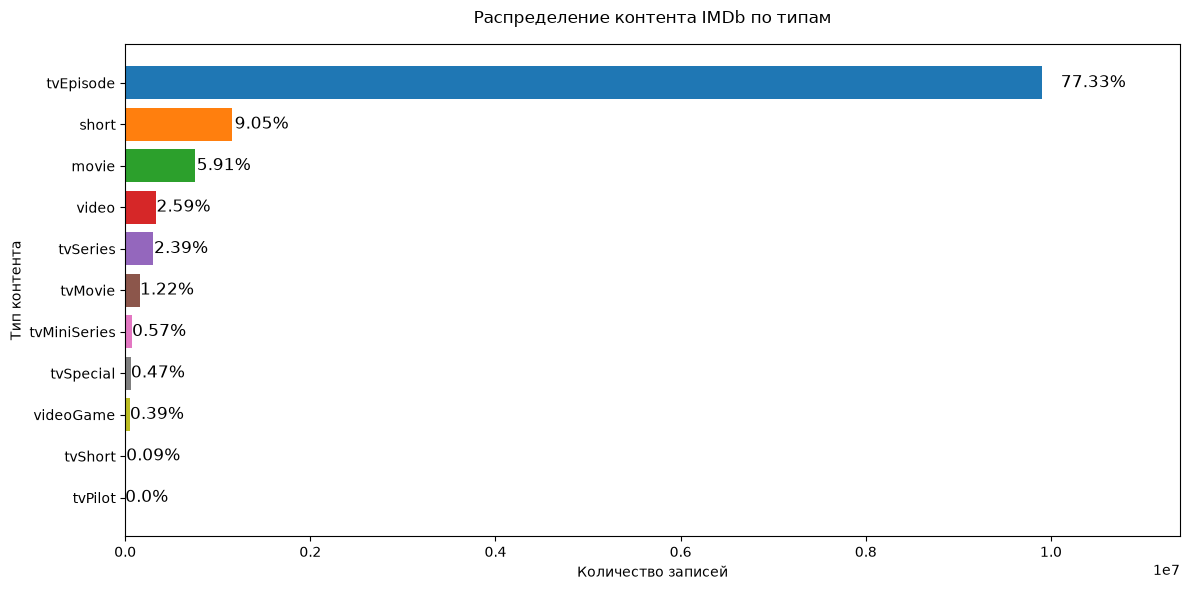

In [20]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.barh(df_types["titletype"], df_types["cnt"],
               color=sns.color_palette())
ax.invert_yaxis()

for i, row in df_types.iterrows():
    ax.text( row["cnt"] * 1.02, i, 
            f"{row['pct']}%",
        va="center",
        fontsize=12
    )

ax.set_title("Распределение контента IMDb по типам", pad=15)
ax.set_xlabel("Количество записей")
ax.set_ylabel("Тип контента")
ax.set_xlim(0, df_types["cnt"].max() * 1.15)

plt.tight_layout()
plt.savefig(REPORTS_DIR / "01_content_types.png", dpi=150, bbox_inches="tight")
plt.show()

### Вывод

- **77% всего контента** — это эпизоды сериалов (*tvEpisode*). Для сравнения, «настоящих» фильмов (*movie*) — только **6%**.
- Это означает, что при анализе «фильмов» нужно **обязательно фильтровать** по `titleType = 'movie'`, иначе эпизоды будут искажать статистику.
- Короткометражки (*short*) занимают второе место (9%) — тоже стоит фильтровать.


## 2. Количество произведений с рейтингом 

**Вопрос:** У какого типа контента чаще всего есть рейтинг IMDb?

In [21]:
query = """
WITH title_stats AS (
    SELECT titletype, COUNT(*) AS total_titles
    FROM title_basics
    GROUP BY titletype
),
rated_stats AS (
    SELECT 
        b.titletype, 
        COUNT(r.tconst) AS rated_titles,
        ROUND(AVG(r.averagerating), 2) AS avg_rating
    FROM title_basics b
    LEFT JOIN title_ratings r ON b.tconst = r.tconst
    GROUP BY b.titletype
)
SELECT 
    t.titletype, 
    t.total_titles, 
    r.rated_titles,
    ROUND(r.rated_titles * 100.0 / t.total_titles, 2) AS rated_percentage,
    r.avg_rating
FROM title_stats t
INNER JOIN rated_stats r ON t.titletype = r.titletype
"""
rated_df = pd.read_sql(query, engine)
rated_df

,titletype,total_titles,rated_titles,rated_percentage,avg_rating
0,movie,757649,348999,46.06,6.15
1,short,1159076,184637,15.93,6.77
2,tvEpisode,9907631,884542,8.93,7.42
3,tvMiniSeries,73153,26178,35.79,7.09
4,tvMovie,156302,57231,36.62,6.57
5,tvPilot,1,0,0.00,NaN
6,tvSeries,305725,114371,37.41,6.78
7,tvShort,11072,2609,23.56,6.73
8,tvSpecial,60414,14396,23.83,6.76
9,video,331502,60214,18.16,6.64


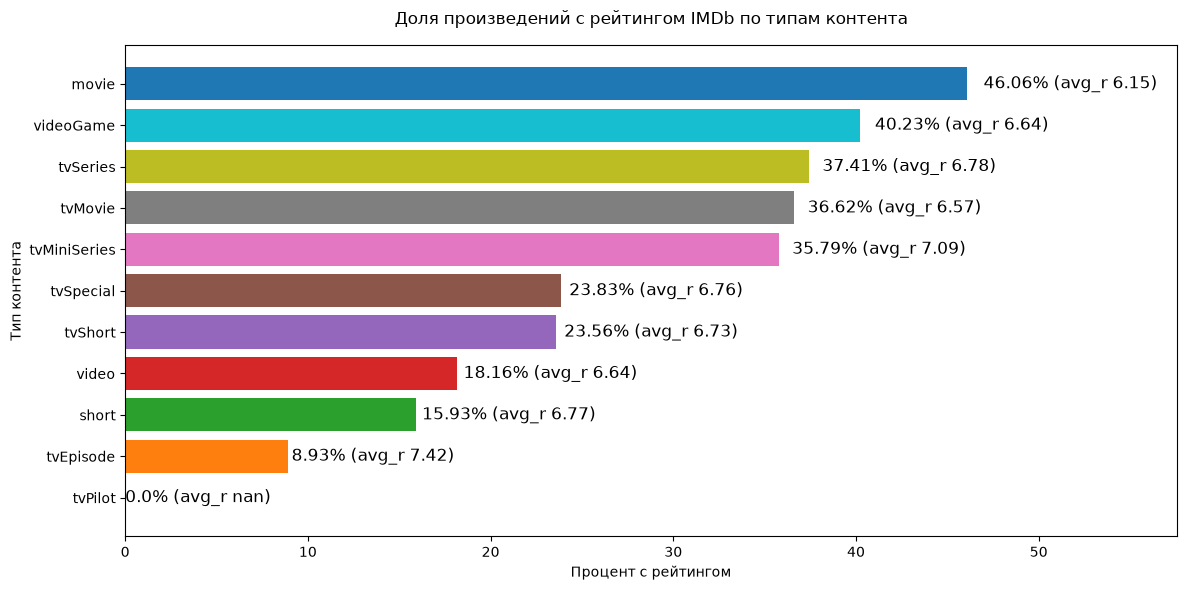

In [22]:
fig, ax = plt.subplots(figsize=(12, 6))

df_sorted = rated_df.sort_values("rated_percentage")
ax.barh(df_sorted["titletype"], df_sorted["rated_percentage"],
               color=sns.color_palette())

for i, (index,row) in enumerate(df_sorted.iterrows()):
    ax.text( row["rated_percentage"] * 1.02, i , 
            f"{row['rated_percentage']}% (avg_r {row['avg_rating']})",
        va="center",
        fontsize=12
    )

ax.set_title("Доля произведений с рейтингом IMDb по типам контента", pad=15)
ax.set_xlabel("Процент с рейтингом")
ax.set_ylabel("Тип контента")
ax.set_xlim(0, df_sorted["rated_percentage"].max() * 1.25)

plt.tight_layout()
plt.savefig(REPORTS_DIR / "02_rated_percentage.png", dpi=150, bbox_inches="tight")
plt.show()

### Вывод

- *movie* — лидер: у **46%** фильмов есть рейтинг IMDb. Это ожидаемо — фильмы активно смотрят и оценивают.
- *tvEpisode* — антилидер: рейтинг есть только у **9%** эпизодов. Большинство эпизодов не набирают достаточно голосов.
- *tvSeries* — 37% сериалов имеют рейтинг.

**Парадокс:** у *tvEpisode* самый **высокий средний рейтинг** (7.42), но при этом самая **низкая доля оценённых**. Это значит, что оценивают только самые популярные эпизоды (пилотные, финальные), а не все подряд.

**Импакт для бизнеса:** если стриминг сравнивает «средний рейтинг эпизодов» и «средний рейтинг фильмов» — он сравнивает несравнимое. Нужно фильтровать по `num_votes` (например, > 1000), чтобы получить репрезентативную выборку.

## 3. Динамика выпуска фильмов по годам

**Вопрос:** как менялось количество выпускаемых фильмов с 1900 по 2026 год?

**Важно:** рассматриваем только *movie* (настоящие фильмы), исключаем эпизоды и короткометражки.

 **Фильтр:** `startYear <= EXTRACT(YEAR FROM CURRENT_DATE)` — чтобы не учитывать анонсы будущих релизов.

In [23]:
query = """
SELECT 
    startyear,
    COUNT(*) AS movies_count,
    ROUND(AVG(r.averagerating), 2) AS avg_rating
FROM title_basics b
LEFT JOIN title_ratings r ON b.tconst = r.tconst
WHERE 
    titletype = 'movie'
    AND startyear IS NOT NULL
    AND startyear >= 1900
    AND startyear <= EXTRACT(YEAR FROM CURRENT_DATE)
GROUP BY startyear
ORDER BY startyear;
"""
df_by_year = pd.read_sql(query, engine)
df_by_year.head(10)

,startyear,movies_count,avg_rating
0,1900,6,3.72
1,1901,8,3.58
2,1902,3,2.53
3,1903,4,4.23
4,1904,3,4.47
5,1905,17,3.55
6,1906,21,3.21
7,1907,18,3.92
8,1908,20,3.67
9,1909,83,3.73


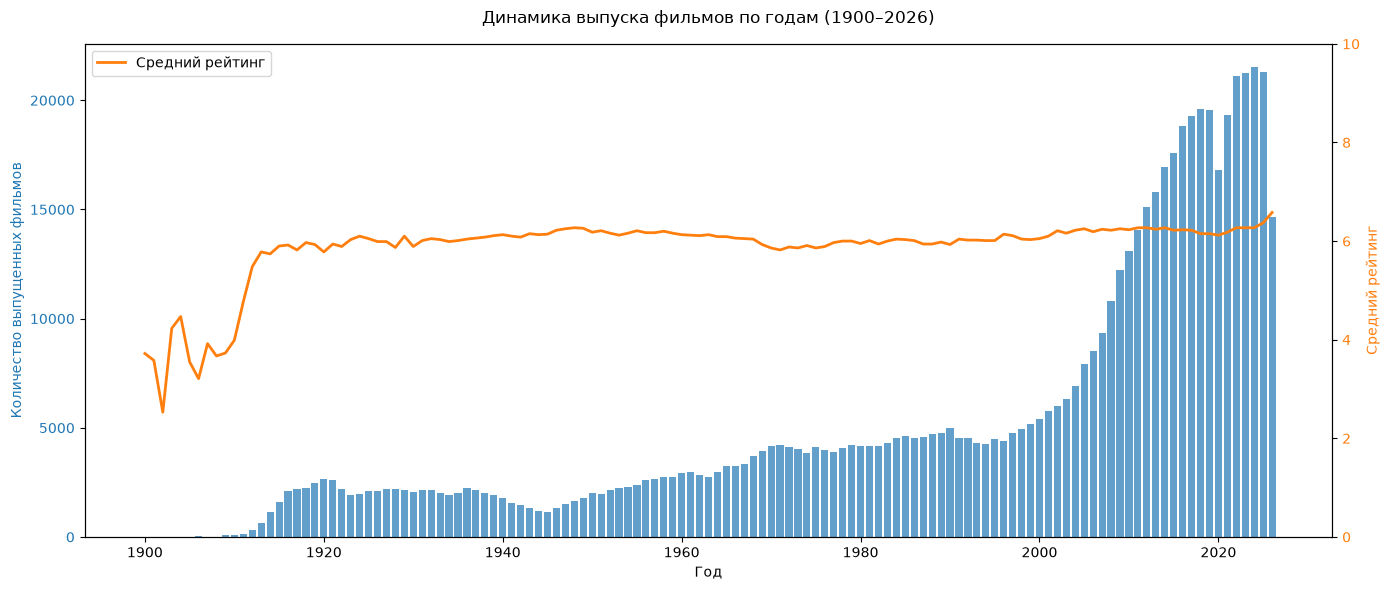

In [24]:
fig, ax1 = plt.subplots(figsize=(14, 6))

# Столбцы: количество фильмов
color1 = sns.color_palette()[0]
ax1.bar(df_by_year["startyear"], df_by_year["movies_count"],
        color=color1, alpha=0.7)
ax1.set_xlabel("Год")
ax1.set_ylabel("Количество выпущенных фильмов", color=color1)
ax1.tick_params(axis="y", labelcolor=color1)

# Линия: средний рейтинг
ax2 = ax1.twinx()
color2 = sns.color_palette()[1]
ax2.plot(df_by_year["startyear"], df_by_year["avg_rating"],
         color=color2, linewidth=2, label="Средний рейтинг")
ax2.set_ylabel("Средний рейтинг", color=color2)
ax2.tick_params(axis="y", labelcolor=color2)
ax2.set_ylim(0, 10)

ax1.set_title("Динамика выпуска фильмов по годам (1900–2026)", pad=15)

# Объединённая легенда
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.tight_layout()
plt.savefig(REPORTS_DIR / "03_movies_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

### Вывод

- **Пик выпуска фильмов** — **2024 год (21 510 фильмов)**. Количество релизов стабильно растёт с 1980-х годов.
- **Провал 2020-2021** — влияние COVID-пандемии. В 2020 году выпустили на **14.1% меньше** фильмов, чем в 2019 (16 811 против 19 574).
- **Средний рейтинг стабилен** — около 6.5-7.0. Колеблется незначительно, несмотря на 100-кратный рост количества релизов.
- **Старше 1950 года** — фильмов мало (несколько сотен в год), поэтому средний рейтинг на графике может «прыгать».

**Импакт для бизнеса:** стриминг видит, что количество контента растёт экспоненциально, а качество (по рейтингу) — нет. Значит, борьба идёт не за количество, а за маркетинг и попадание в топ.

## 4. Топ-10 жанров по количеству фильмов

**Вопрос:** какие жанры доминируют на IMDb?

**Метод:** используем нормализованную таблицу *title_genres* (связь многие ко многим, создана в `04_Genres_Normalization.sql`).

**Важно:** фильтруем только `movie` и только с рейтингом `num_votes >= 1000`, чтобы не учитывать мусорные записи.

In [25]:
query = """
SELECT 
    g.genre_name,
    COUNT(DISTINCT b.tconst) AS movies_count,
    ROUND(AVG(r.averagerating), 2) AS avg_rating
FROM title_basics b
JOIN title_genres tg ON b.tconst = tg.tconst
JOIN genres g ON tg.genre_id = g.genre_id
JOIN title_ratings r ON b.tconst = r.tconst
WHERE 
    b.titletype = 'movie'
    AND r.numvotes >= 1000
GROUP BY g.genre_name
ORDER BY movies_count DESC
LIMIT 10
"""
df_genres = pd.read_sql(query, engine)
df_genres

,genre_name,movies_count,avg_rating
0,Drama,27371,6.49
1,Comedy,16350,6.15
2,Action,8925,5.93
3,Crime,8180,6.30
4,Romance,8167,6.39
5,Thriller,7522,5.82
6,Horror,6647,5.25
7,Adventure,5316,6.10
8,Mystery,4170,5.98
9,Fantasy,2660,5.94


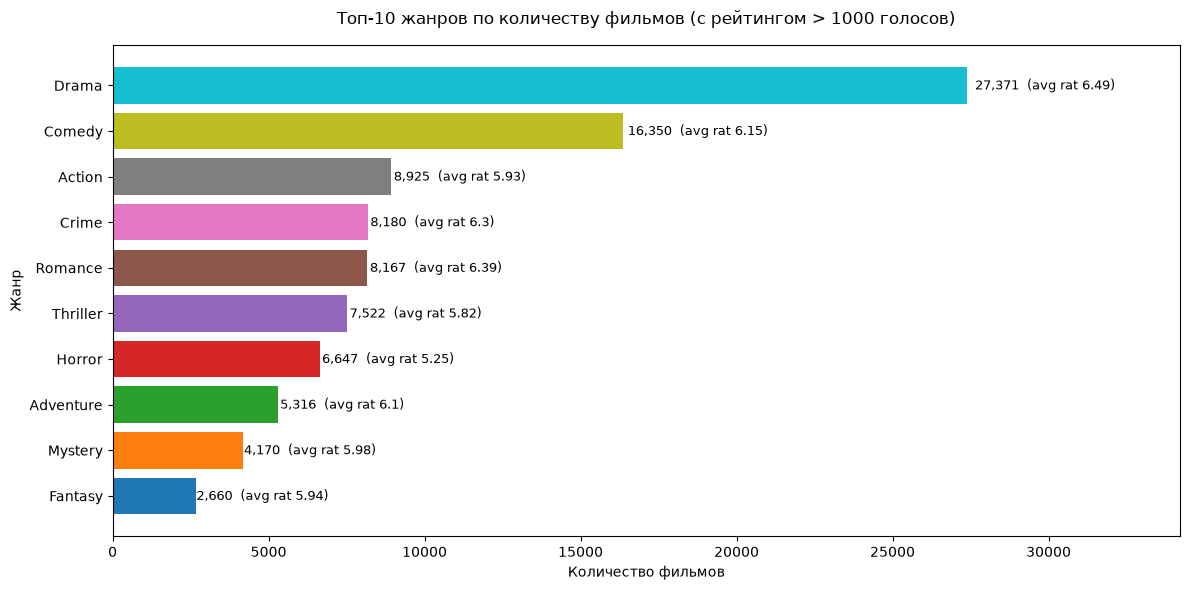

In [26]:
fig, ax = plt.subplots(figsize=(12, 6))

df_genres_sorted = df_genres.sort_values("movies_count")
bars = ax.barh(df_genres_sorted["genre_name"], df_genres_sorted["movies_count"],
               color=sns.color_palette())

# Подписи со средним рейтингом
for bar, count, avg in zip(bars, df_genres_sorted["movies_count"], df_genres_sorted["avg_rating"]):
    ax.text(bar.get_width() * 1.01, bar.get_y() + bar.get_height()/2,
            f"{count:,}  (avg rat {avg})", va="center", fontsize=9)
    
ax.set_title("Топ-10 жанров по количеству фильмов (с рейтингом > 1000 голосов)", pad=15)
ax.set_xlabel("Количество фильмов")
ax.set_ylabel("Жанр")
ax.set_xlim(0, df_genres_sorted["movies_count"].max() * 1.25)

plt.tight_layout()
plt.savefig(REPORTS_DIR / "04_top_genres.png", dpi=150, bbox_inches="tight")
plt.show()

### Вывод

- **Drama** — абсолютный лидер (**27 371 фильм**). Это самый массовый жанр на IMDb.
- **Comedy** (16 350) и **Action** (8 925) — на втором и третьем местах.
- **Horror** — интересный факт: жанр на 6-м месте по количеству (6 647 фильмов), но **средний рейтинг ниже всех** в топ-10 (5.25). Ужасы смотрят массово, но оценивают низко.
- **Adventure, Mystery, Fantasy** — замыкают топ-10.

**Импакт для бизнеса:** стриминг, который хочет массовый контент, должен инвестировать в драмы и комедии. Но если нужен высокорейтинговый контент — смотреть на другие жанры (см. раздел 5).

## 5. Рейтинг по жанрам

**Вопрос:** какие жанры получают самые высокие оценки?

**Метод:** тот же фильтр — только фильмы с `numVotes >= 1000`.

**Гипотеза:** документалки и исторические фильмы должны лидировать.

In [27]:
query = """
SELECT 
    g.genre_name,
    COUNT(DISTINCT b.tconst) AS movies_count,
    ROUND(AVG(r.averagerating), 2) AS avg_rating,
    ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY r.averagerating)::numeric, 2) AS median_rating
FROM title_basics b
JOIN title_genres tg ON b.tconst = tg.tconst
JOIN genres g ON tg.genre_id = g.genre_id
JOIN title_ratings r ON b.tconst = r.tconst
WHERE 
    b.titletype = 'movie'
    AND r.numvotes >= 1000
GROUP BY g.genre_name
HAVING COUNT(DISTINCT b.tconst) >= 1000
ORDER BY avg_rating DESC;
"""
df_ratings = pd.read_sql(query, engine)
df_ratings

,genre_name,movies_count,avg_rating,median_rating
0,Documentary,2573,7.19,7.3
1,Biography,2602,6.90,7.0
2,History,1937,6.82,6.9
3,War,1231,6.77,6.9
4,Music,1489,6.70,6.8
5,Animation,1627,6.63,6.8
6,Drama,27371,6.49,6.6
7,Romance,8167,6.39,6.5
8,Crime,8180,6.30,6.4
9,Family,2061,6.22,6.4


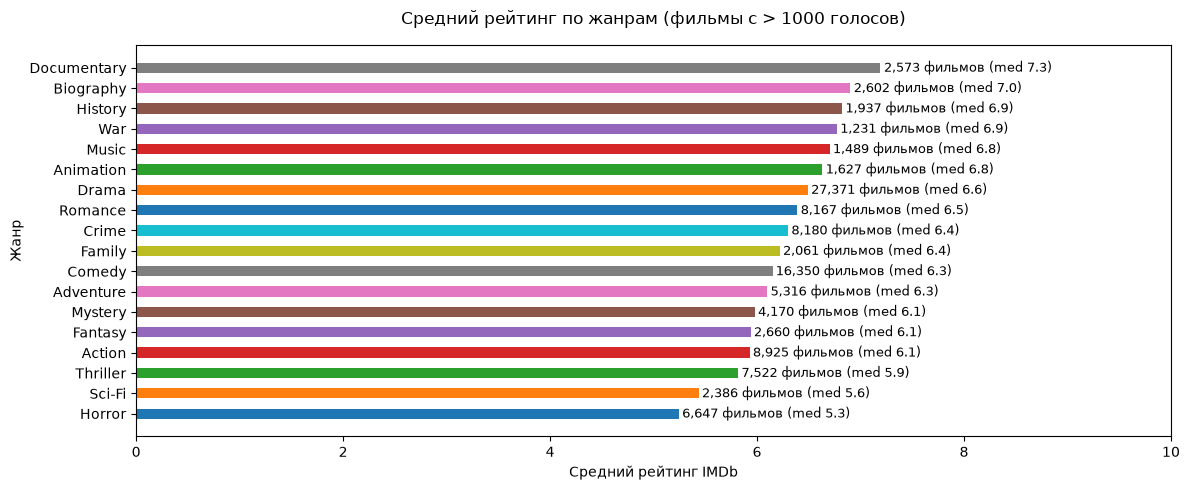

In [28]:
fig, ax = plt.subplots(figsize=(12, 5))

df_sorted = df_ratings.sort_values("avg_rating", ascending=True)
bars = ax.barh(df_sorted["genre_name"], df_sorted["avg_rating"], height= 0.5,
               color=sns.color_palette())

# Подписи с количеством фильмов
for bar, count, med in zip(bars, df_sorted["movies_count"], df_sorted["median_rating"]):
    width = bar.get_width()
    ax.text(width * 1.005, bar.get_y() + bar.get_height()/2,
            f"{count:,} фильмов (med {med})", va="center", fontsize=9)

ax.set_title("Средний рейтинг по жанрам (фильмы с > 1000 голосов)", pad=15)
ax.set_xlabel("Средний рейтинг IMDb")
ax.set_ylabel("Жанр")
ax.set_xlim(0, 10)

plt.tight_layout()
plt.savefig(REPORTS_DIR / "05_rating_by_genre.png", dpi=150, bbox_inches="tight")
plt.show()

### Вывод

- **Documentary** — лидер по среднему рейтингу (**7.19**), медиана **7.3**. Документальное кино редко разочаровывает: сюда попадают только реально интересные истории.
- **Biography** (6.90), **History** (6.82), **War** (6.77) — тоже в топе. Это «серьёзные» жанры с преданной аудиторией.
- **Horror** (5.25) и **Sci-Fi** (5.44) — внизу списка. Их смотрят массово, но оценивают низко.
- **Разброс** между лучшим и худшим жанром **~2 балла** (7.19 vs 5.25). Для IMDb это большое различие.

**Импакт для бизнеса:** продюсер видит, что вложение в документалку с высокой вероятностью окупится рейтингом. А ужасы — это про массовость и деньги, но не про оценку критиков.

## 6. Связь длительности фильма и рейтинга

**Вопрос:** есть ли зависимость между длительностью фильма и его рейтингом?

**Гипотеза:** более длинные фильмы оценивают выше — в них больше «глубины».

**Фильтр:** только `movie`, `runtimeMinutes` в разумных пределах (60-240 минут), `numVotes >= 1000`.

In [29]:
query = """
SELECT 
    b.tconst,
    b.primarytitle,
    b.startyear,
    b.runtimeminutes,
    r.averagerating,
    r.numvotes
FROM title_basics b
JOIN title_ratings r ON b.tconst = r.tconst
WHERE 
    b.titletype = 'movie'
    AND b.runtimeminutes BETWEEN 60 AND 240
    AND r.numvotes >= 1000
    AND b.startyear >= 1950;
"""
df_runtime = pd.read_sql(query, engine)
print(f"Всего фильмов: {len(df_runtime):,}")

# Корреляция Пирсона
from scipy.stats import pearsonr
corr, p_value = pearsonr(df_runtime["runtimeminutes"], df_runtime["averagerating"])
print(f"Корреляция Пирсона: r = {corr:.3f} (p-value = {p_value:.2e})")

Всего фильмов: 46,565
Корреляция Пирсона: r = 0.291 (p-value = 0.00e+00)


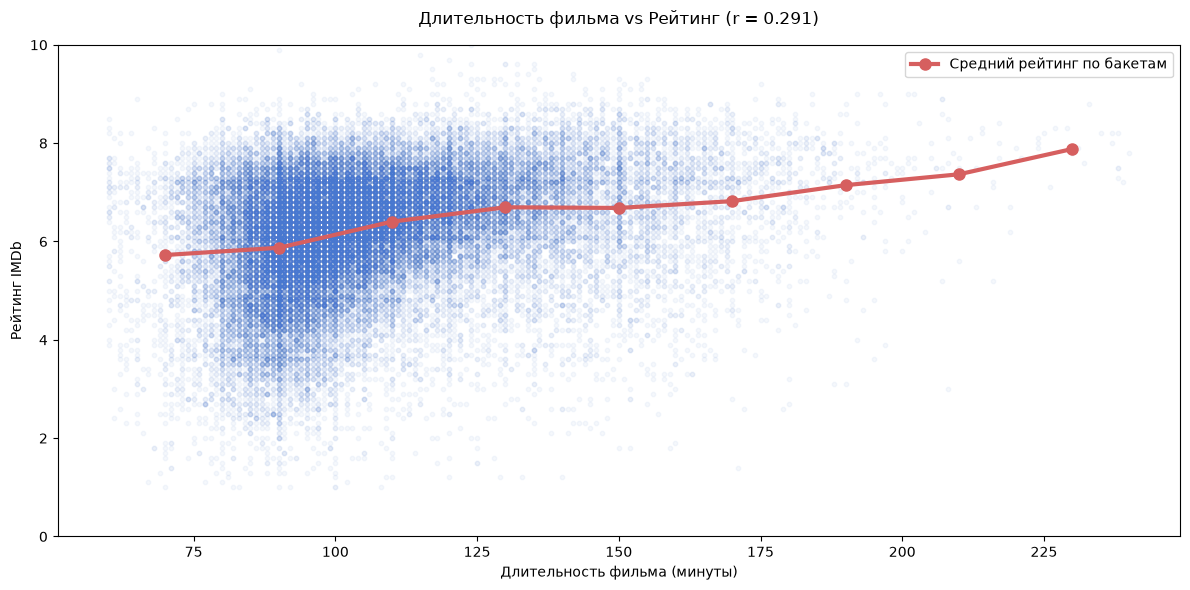

In [30]:
fig, ax = plt.subplots(figsize=(12, 6))

# Scatter с прозрачностью (точек много)
ax.scatter(df_runtime["runtimeminutes"], df_runtime["averagerating"],
           alpha=0.05, s=10, color=sns.color_palette("muted")[0])

# Средний рейтинг по бакетам длительности
df_runtime["runtime_bucket"] = pd.cut(df_runtime["runtimeminutes"],
                                        bins=range(60, 250, 20))
bucket_avg = df_runtime.groupby("runtime_bucket", observed=True)["averagerating"].mean()

bucket_centers = [interval.mid for interval in bucket_avg.index]
ax.plot(bucket_centers, bucket_avg.values,
        color=sns.color_palette("muted")[3], linewidth=3, marker="o",
        markersize=8, label="Средний рейтинг по бакетам")

ax.set_title(f"Длительность фильма vs Рейтинг (r = {corr:.3f})", pad=15)
ax.set_xlabel("Длительность фильма (минуты)")
ax.set_ylabel("Рейтинг IMDb")
ax.set_ylim(0, 10)
ax.legend()

plt.tight_layout()
plt.savefig(REPORTS_DIR / "06_runtime_vs_rating.png", dpi=150, bbox_inches="tight")
plt.show()

### Вывод

- **Слабая положительная корреляция** (**r = 0.29**). Длинные фильмы **чуть** выше оценивают, но зависимости почти нет.
- **Средний рейтинг растёт** с 6.0 (60 минут) до ~7.0 (180+ минут). Но это скорее про то, что длинные фильмы снимают опытные режиссёры.
- **Короткие фильмы (<90 мин)** чаще получают рейтинг ниже 6.0 — это либо B-муви, либо неудавшиеся эксперименты.
- **Разброс огромен**: при любой длительности есть фильмы с рейтингом и 3.0, и 9.0.

**Импакт для бизнеса:** стриминг не должен настаивать «делайте длиннее — будет лучше». Зависимость слабая. Маркетинг, актёры, режиссёр влияют сильнее.

## 7. Топ-10 лучших фильмов всех времён

**Вопрос:** какие фильмы заслужили самые высокие оценки?

**Метод:** фильмы с **> 100 000 голосов** (чтобы отсечь «накрутки» и нишевое кино) и рейтингом ≥ 8.0.

**Почему фильтр по голосам:** фильм с рейтингом 10.0 и 20 голосами — не показатель. Нам нужны фильмы, которые посмотрели миллионы.

In [31]:
query = """
SELECT 
    b.primarytitle,
    b.startyear,
    b.runtimeminutes,
    b.genres,
    r.averagerating,
    r.numvotes
FROM title_basics b
JOIN title_ratings r ON b.tconst = r.tconst
WHERE 
    b.titletype = 'movie'
    AND r.numvotes >= 100000
    AND r.averagerating >= 8.0
ORDER BY r.averagerating DESC, r.numvotes DESC
LIMIT 10;
"""
df_top = pd.read_sql(query, engine)
df_top

,primarytitle,startyear,runtimeminutes,genres,averagerating,numvotes
0,The Shawshank Redemption,1994,142,Drama,9.3,3242062
1,The Godfather,1972,175,"Crime,Drama",9.2,2258307
2,The Dark Knight,2008,152,"Crime,Thriller",9.1,3230258
3,The Lord of the Rings: The Return of the King,2003,201,"Adventure,Drama,Fantasy",9.0,2195039
4,Schindler's List,1993,196,"Biography,Drama,History",9.0,1604631
5,The Godfather Part II,1974,202,"Crime,Drama",9.0,1514580
6,12 Angry Men,1957,96,"Crime,Drama",9.0,1004022
7,The Lord of the Rings: The Fellowship of the Ring,2001,178,"Adventure,Drama,Fantasy",8.9,2238910
8,Inception,2010,148,"Adventure,Sci-Fi,Thriller",8.8,2871757
9,Fight Club,1999,139,"Crime,Drama,Thriller",8.8,2664323


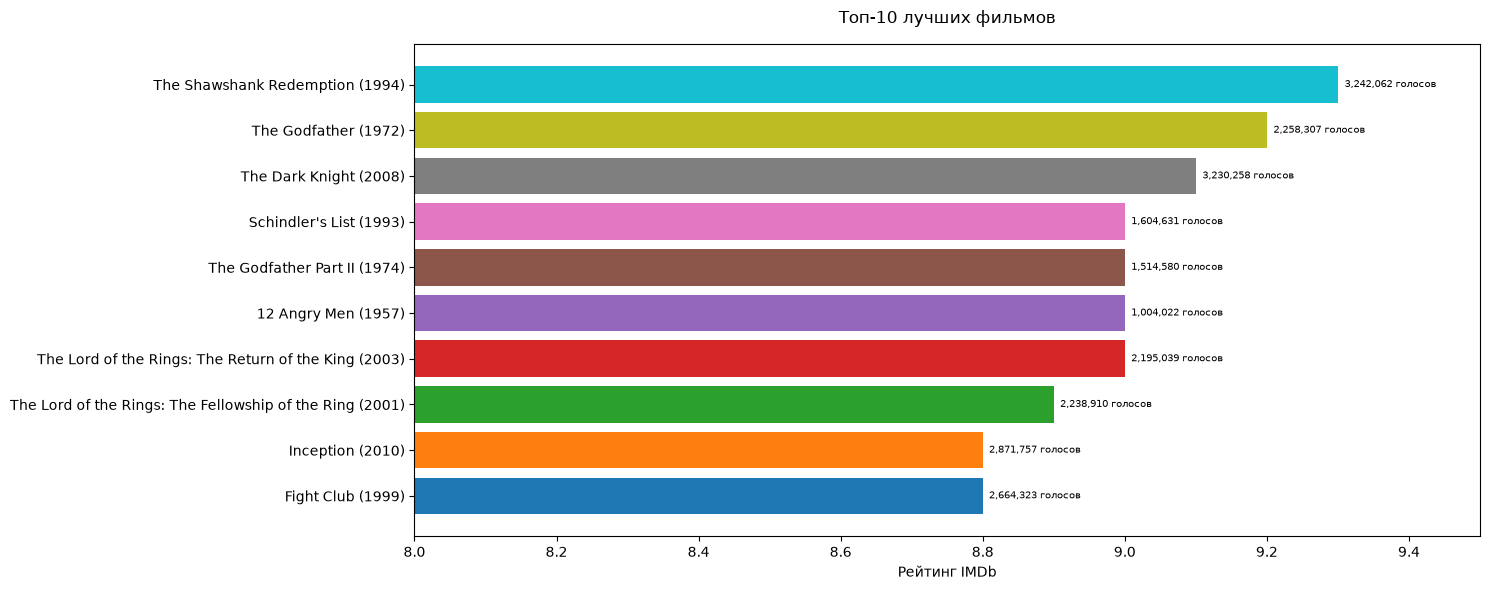

In [32]:
fig, ax = plt.subplots(figsize=(15, 6))

df_top_sorted = df_top.sort_values("averagerating")
labels = [f"{row['primarytitle']} ({row['startyear']})" for i, row in df_top_sorted.iterrows()]
bars = ax.barh(labels, df_top_sorted["averagerating"],
               color=sns.color_palette())

for bar, votes in zip(bars, df_top_sorted["numvotes"]):
    ax.text(bar.get_width() * 1.001, bar.get_y() + bar.get_height()/2,
            f"{votes:,} голосов", va="center", fontsize=7)

ax.set_title("Топ-10 лучших фильмов", pad=15)
ax.set_xlabel("Рейтинг IMDb")
ax.set_xlim(8.0, 9.5)

plt.tight_layout()
plt.savefig(REPORTS_DIR / "07_top_movies.png", dpi=150, bbox_inches="tight")
plt.show()

### Вывод

- **The Shawshank Redemption** — лидер с рейтингом **9.3** и **3.2 млн голосов**. Это легенда IMDb.
- **The Godfather** (9.2) и **The Dark Knight** (9.1) — на 2-3 местах.
- **Классика 90-х и 2000-х** доминирует: 7 из 10 фильмов выпущены до 2010 года.
- **Феномен:** в топ-10 нет ни одного фильма после 2010 года. Это не значит, что новых хороших фильмов нет — просто им нужно время, чтобы набрать голоса.

**Импакт для бизнеса:** если продюсер хочет создать вечный контент, нужно ориентироваться на эти фильмы. Но попытки «повторить успех» редко работают — Топ-10 это уникальные исключения.

# Ключевые выводы

**1. Структура контента на IMDb**
- 77% записей — это эпизоды сериалов. Настоящих фильмов (*movie*) — только **6%**.

**2. Рейтинги и оценки**
- У **46%** фильмов есть рейтинг IMDb. Это самый высокий показатель среди всех типов контента.
- У **9%** эпизодов есть рейтинг. Это самая низкая доля — оценивают только самые популярные эпизоды.

**3. Динамика по годам**
- **Пик выпуска** — **2024 год (21 510 фильмов)**.
- **COVID-2020** дал падение **-14.1%** (16 811 vs 19 574 в 2019).
- **Средний рейтинг стабилен** (6.5-7.0) — количество контента растёт, а качество нет.

**4-5. Жанры и рейтинг по жанрам**
- **Drama** — лидер по количеству фильмов (**27 371**).
- **Documentary** — лидер по среднему рейтингу (**7.19**).
- **Horror** (5.25) и **Sci-Fi** (5.44) — антилидеры по рейтингу.

**6. Длительность и рейтинг**
- Корреляция слабая (**r ~ 0.29**). Длина фильма — **плохой предиктор** качества.
- Маркетинг, актёры, режиссёр важнее, чем «сделать длиннее».

**7. Топ-10 лучших**
- **The Shawshank Redemption** — лидер (9.3, 3.2 млн голосов).
- Классика 90-х и 2000-х доминирует. Новых фильмов в топе нет.

### Бизнес-рекомендации

1. **Для стриминга:** инвестировать в **документалки** — высокий рейтинг при низком бюджете.
2. **Для продюсеров:** не гнаться за количеством. Ориентир — качество и попадание в нишу.
3. **Для маркетологов:** топ-100 фильмов нужно продвигать десятки лет — они не устаревают.